# 01 - Exploratory data analysis and data quality

**Project:** credit risk scoring | **Issues:** #4 (EDA), #5 (missing values and outliers), #6 (data split)

**Rules followed in this notebook**
1. Exact duplicates are removed *before* the split, so the same row cannot land in both train and test.
2. The stratified split is done **first**. Everything after it (statistics, plots, decisions) uses the **training set only**. The validation and test sets are not looked at, which avoids leaking information into cleaning and modeling decisions.
3. Reusable code lives in `src/`; this notebook explores and tells the story.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.load import TARGET, load_raw
from src.data.clean import AGE_MAX, EMP_LENGTH_MAX, impossible_mask, remove_impossible_values
from src.data.split import load_split, make_splits, save_splits

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the raw data and remove exact duplicates

In [2]:
raw = load_raw()
n_dup = int(raw.duplicated().sum())
print(f"Raw shape: {raw.shape} | exact duplicate rows: {n_dup} ({n_dup / len(raw):.2%})")

df = raw.drop_duplicates().reset_index(drop=True)
print(f"After removing exact duplicates: {df.shape}")

# Are there rows with identical features but a different label? (would indicate label noise)
features = [c for c in df.columns if c != TARGET]
same_features = df.duplicated(subset=features, keep=False)
conflicting = (
    df[same_features].groupby(features, dropna=False)[TARGET].nunique().gt(1).sum()
)
print(f"Groups with identical features but conflicting labels: {conflicting}")

Raw shape: (32581, 12) | exact duplicate rows: 165 (0.51%)
After removing exact duplicates: (32416, 12)
Groups with identical features but conflicting labels: 0


**Decision:** exact duplicates are dropped before splitting. The dataset has no applicant identifier, so identical rows could in theory be different people, but keeping them would let the same row appear in train and test and inflate the test score.

## 2. Stratified train / validation / test split (issue #6)

In [3]:
train, val, test = make_splits(df)   # 60% / 20% / 20%, stratified on the target, seed 42
save_splits(train, val, test)        # data/processed/{train,val,test}.csv (not versioned)

for name, part in {"train": train, "validation": val, "test": test}.items():
    print(f"{name:11s} rows = {len(part):6d} | default rate = {part[TARGET].mean():.4f}")

# From here on, only the training set is explored.
eda = train.copy()
del val, test

train       rows =  19449 | default rate = 0.2187
validation  rows =   6483 | default rate = 0.2187
test        rows =   6484 | default rate = 0.2187


## 3. Target balance

In [4]:
balance = eda[TARGET].value_counts(normalize=True).rename("share").to_frame()
display(balance)
print(f"A model that always predicts 'no default' would reach {balance.loc[0, 'share']:.1%} accuracy, so accuracy is not a useful metric here.")

,share
loan_status,
0,0.781326
1,0.218674


A model that always predicts 'no default' would reach 78.1% accuracy, so accuracy is not a useful metric here.


## 4. Numeric variables

In [5]:
num_cols = [c for c in eda.select_dtypes("number").columns if c != TARGET]
display(eda[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
person_age,19449.0,27.743020,6.373373,20.00,21.00,23.00,26.00,30.00,50.00,144.00
person_income,19449.0,66107.536943,67504.335440,4000.00,14400.00,38492.00,55000.00,79000.00,225000.00,6000000.00
person_emp_length,18908.0,4.786440,4.205966,0.00,0.00,2.00,4.00,7.00,18.00,123.00
loan_amnt,19449.0,9589.951926,6289.373825,500.00,1000.00,5000.00,8000.00,12300.00,28000.00,35000.00
loan_int_rate,17608.0,11.023056,3.230475,5.42,5.42,7.90,10.99,13.48,18.39,23.22
loan_percent_income,19449.0,0.170361,0.106892,0.00,0.02,0.09,0.15,0.23,0.50,0.78
cb_person_cred_hist_length,19449.0,5.796133,4.051871,2.00,2.00,3.00,4.00,8.00,17.00,30.00


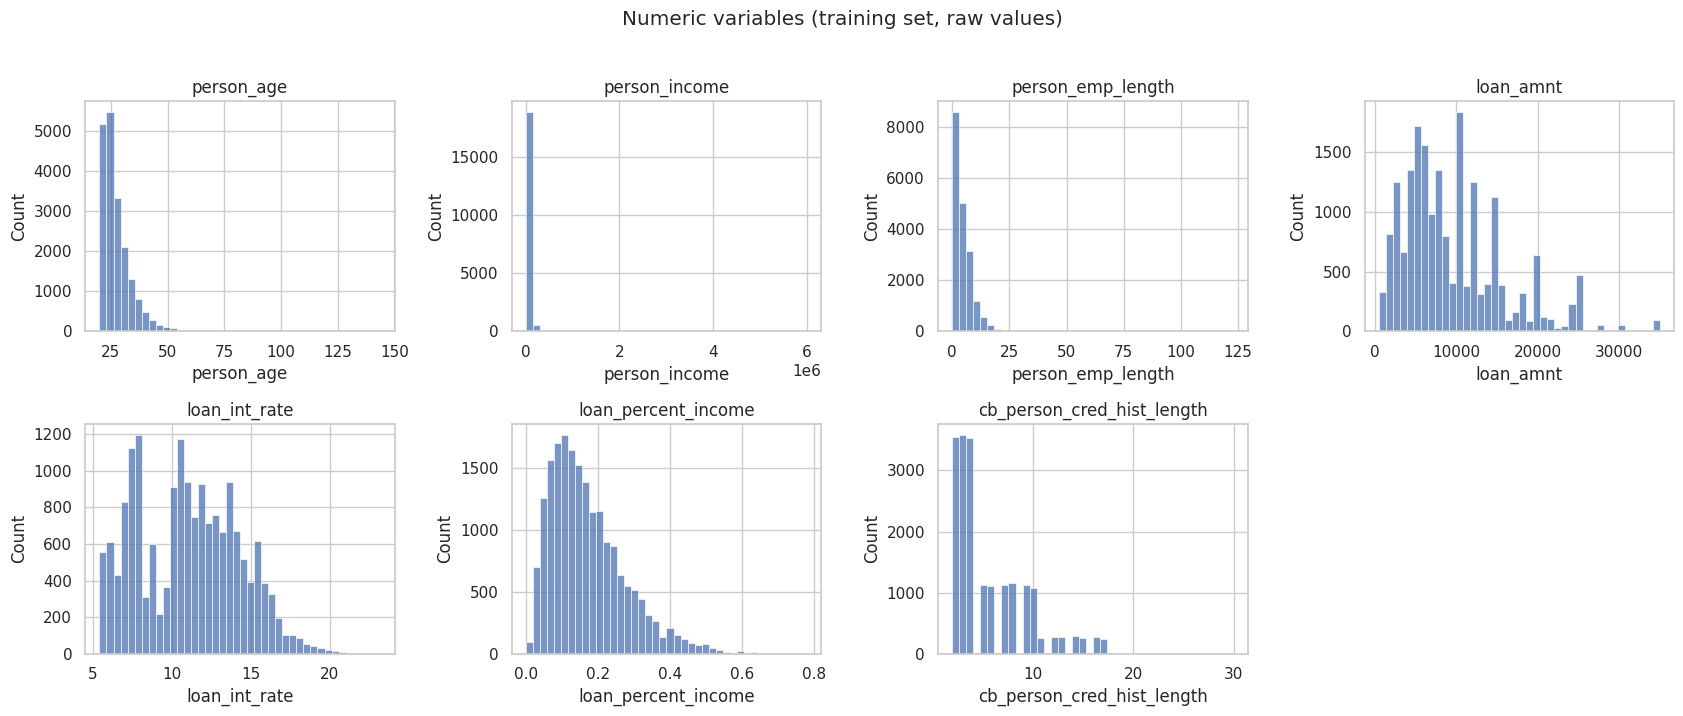

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(eda[col], bins=40, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle("Numeric variables (training set, raw values)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_numeric_distributions.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Categorical variables

In [7]:
cat_cols = list(eda.select_dtypes(include=["object", "string"]).columns)
for col in cat_cols:
    print(f"--- {col} ---")
    print(eda[col].value_counts(normalize=True).round(4).to_string())
    print()

--- person_home_ownership ---
person_home_ownership
RENT        0.5031
MORTGAGE    0.4153
OWN         0.0784
OTHER       0.0032

--- loan_intent ---
loan_intent
EDUCATION            0.1981
MEDICAL              0.1872
VENTURE              0.1790
PERSONAL             0.1681
DEBTCONSOLIDATION    0.1599
HOMEIMPROVEMENT      0.1078

--- loan_grade ---
loan_grade
A    0.3308
B    0.3202
C    0.1990
D    0.1108
E    0.0301
F    0.0071
G    0.0020

--- cb_person_default_on_file ---
cb_person_default_on_file
N    0.823
Y    0.177



## 6. Default rate by categorical variable

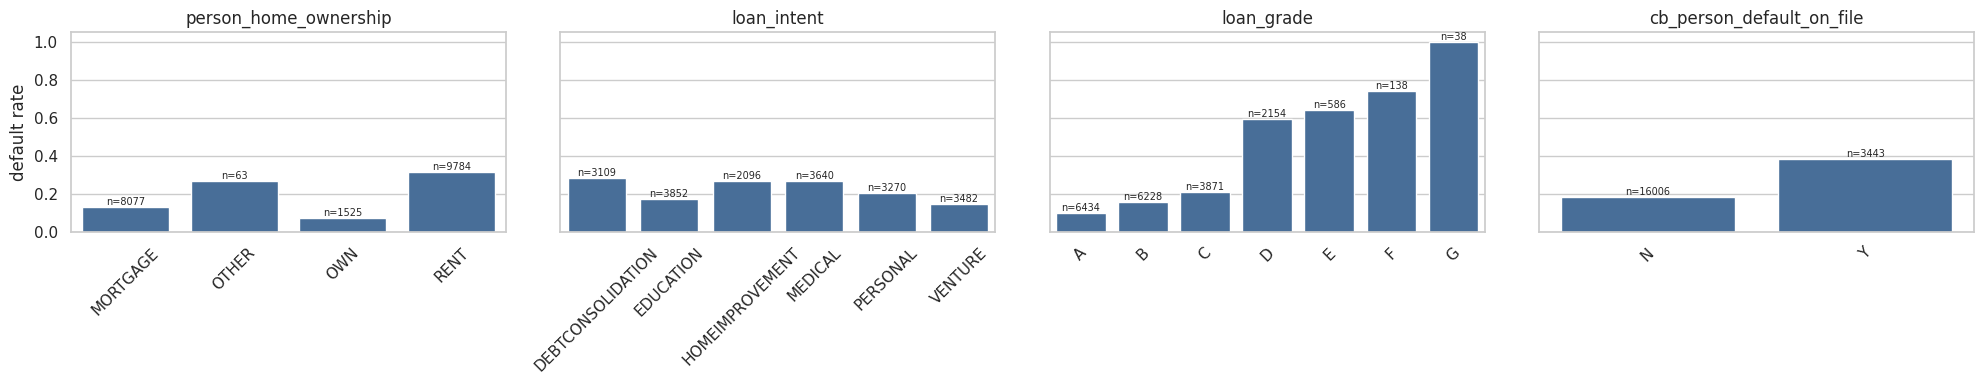

Default rate by person_home_ownership


,default_rate,n
person_home_ownership,,
MORTGAGE,0.1293,8077
OTHER,0.2698,63
OWN,0.0748,1525
RENT,0.3146,9784


Default rate by loan_intent


,default_rate,n
loan_intent,,
DEBTCONSOLIDATION,0.2821,3109
EDUCATION,0.1732,3852
HOMEIMPROVEMENT,0.2705,2096
MEDICAL,0.2670,3640
PERSONAL,0.2031,3270
VENTURE,0.1453,3482


Default rate by loan_grade


,default_rate,n
loan_grade,,
A,0.1002,6434
B,0.1601,6228
C,0.2100,3871
D,0.5956,2154
E,0.6399,586
F,0.7391,138
G,1.0000,38


Default rate by cb_person_default_on_file


,default_rate,n
cb_person_default_on_file,,
N,0.1836,16006
Y,0.3816,3443


In [8]:
fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4), sharey=True)
for ax, col in zip(np.atleast_1d(axes), cat_cols):
    rate = eda.groupby(col)[TARGET].agg(["mean", "size"]).sort_index()
    sns.barplot(x=rate.index, y=rate["mean"], ax=ax, color="#3b6ea5")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("default rate")
    ax.tick_params(axis="x", rotation=45)
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, m, f"n={n}", ha="center", va="bottom", fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_default_rate_categorical.png", dpi=130, bbox_inches="tight")
plt.show()

for col in cat_cols:
    print(f"Default rate by {col}")
    display(eda.groupby(col)[TARGET].agg(default_rate="mean", n="size").round(4))

## 7. Default rate by numeric variable (binned)

Default rate by person_age


,default_rate,n
person_age,,
"(0, 22]",0.2646,2861
"(22, 25]",0.2167,6299
"(25, 28]",0.2101,3836
"(28, 32]",0.2001,3093
"(32, 40]",0.2099,2463
"(40, 60]",0.2100,862
"(60, 200]",0.2286,35


Default rate by person_income


,default_rate,n
person_income,,
"(3999.999, 28800.0]",0.4564,2020
"(28800.0, 35000.0]",0.3904,1926
"(35000.0, 42000.0]",0.2333,2100
"(42000.0, 49000.0]",0.2424,1819
"(49000.0, 55000.0]",0.1834,1903
"(55000.0, 63000.0]",0.1761,1919
"(63000.0, 73000.0]",0.1626,1962
"(73000.0, 85908.0]",0.1408,1910
"(85908.0, 110000.0]",0.1027,1957


Default rate by loan_int_rate


...

,default_rate,n
loan_percent_income,,
"(-0.001, 0.05]",0.1003,2053
"(0.05, 0.08]",0.1292,2423
"(0.08, 0.1]",0.1315,1764
"(0.1, 0.12]",0.1310,1611
"(0.12, 0.15]",0.1264,2405
"(0.15, 0.18]",0.1808,1952
"(0.18, 0.21]",0.1898,1733
"(0.21, 0.25]",0.1910,1770
"(0.25, 0.32]",0.3501,1891


Default rate by loan_amnt


,default_rate,n
loan_amnt,,
"(499.999, 3000.0]",0.2111,2378
"(3000.0, 4400.0]",0.2044,1541
"(4400.0, 5400.0]",0.1946,1917
"(5400.0, 6800.0]",0.1599,1982
"(6800.0, 8000.0]",0.1754,2166
"(8000.0, 10000.0]",0.1965,2829
"(10000.0, 12000.0]",0.1913,1725
"(12000.0, 14800.0]",0.2659,1023
"(14800.0, 19000.0]",0.2719,1964


Default rate by person_emp_length


,default_rate,n
person_emp_length,,
"(-1, 0]",0.2852,2461
"(0, 2]",0.2621,4052
"(2, 5]",0.2021,5512
"(5, 10]",0.1805,5142
"(10, 20]",0.1578,1673
"(20, 200]",0.2059,68


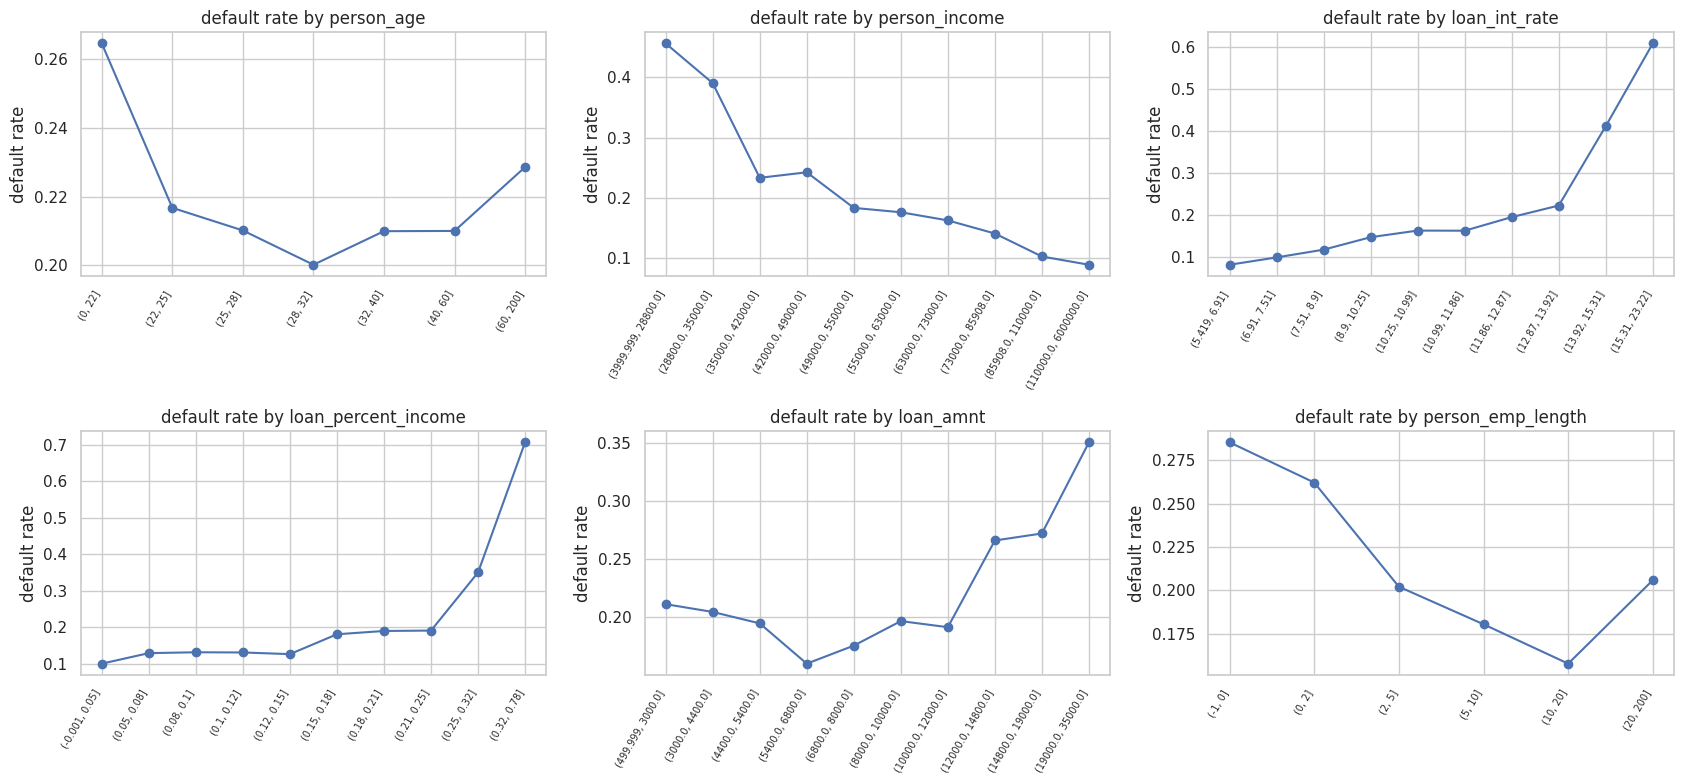

In [9]:
def binned_rate(series, bins=None, q=None):
    if q is not None:
        groups = pd.qcut(series, q=q, duplicates="drop")
    else:
        groups = pd.cut(series, bins=bins)
    return eda.groupby(groups, observed=True)[TARGET].agg(default_rate="mean", n="size")

specs = {
    "person_age": dict(bins=[0, 22, 25, 28, 32, 40, 60, 200]),
    "person_income": dict(q=10),
    "loan_int_rate": dict(q=10),
    "loan_percent_income": dict(q=10),
    "loan_amnt": dict(q=10),
    "person_emp_length": dict(bins=[-1, 0, 2, 5, 10, 20, 200]),
}
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (col, kw) in zip(axes.ravel(), specs.items()):
    t = binned_rate(eda[col], **kw)
    print(f"Default rate by {col}")
    display(t.round(4))
    ax.plot(range(len(t)), t["default_rate"].values, marker="o")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=60, ha="right", fontsize=7)
    ax.set_title(f"default rate by {col}")
    ax.set_ylabel("default rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_default_rate_numeric.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. Correlations (Spearman)

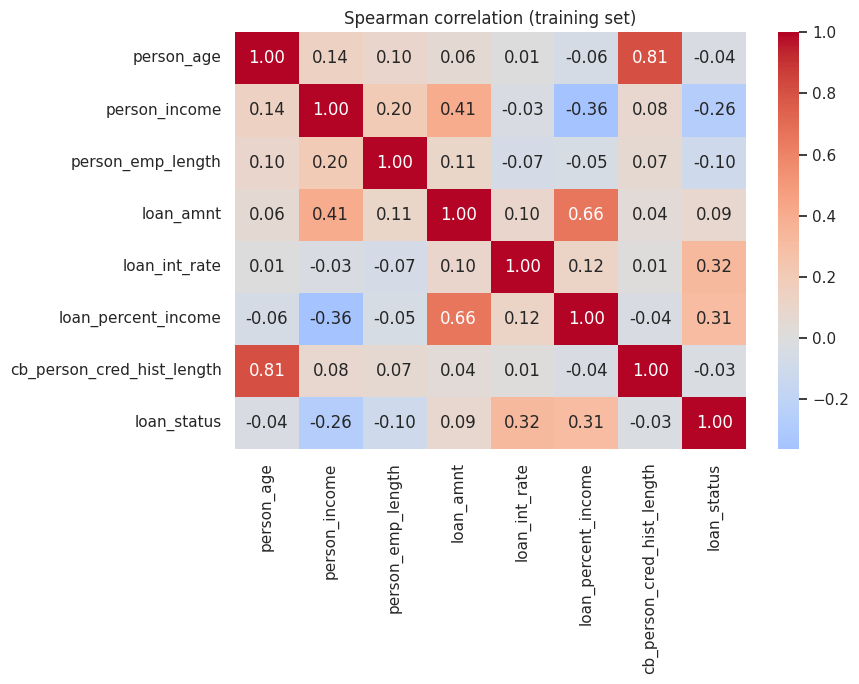

,spearman with target
loan_int_rate,0.322
loan_percent_income,0.310
person_income,-0.264
person_emp_length,-0.099
loan_amnt,0.086
person_age,-0.036
cb_person_cred_hist_length,-0.027


In [10]:
corr = eda[num_cols + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation (training set)")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_correlation.png", dpi=130, bbox_inches="tight")
plt.show()

display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("spearman with target"))

## 9. Missing values (issue #5)

In [11]:
missing = eda.isna().sum().to_frame("missing")
missing["share"] = (missing["missing"] / len(eda)).round(4)
display(missing[missing["missing"] > 0])

for col in ["person_emp_length", "loan_int_rate"]:
    m = eda[col].isna()
    print(
        f"{col}: default rate when missing = {eda.loc[m, TARGET].mean():.4f} "
        f"| when present = {eda.loc[~m, TARGET].mean():.4f}"
    )

print("\nShare of missing loan_int_rate by loan_grade:")
display(eda.assign(int_rate_missing=eda["loan_int_rate"].isna()).groupby("loan_grade")["int_rate_missing"].mean().round(4).to_frame("share missing"))
print("Share of missing person_emp_length by person_home_ownership:")
display(eda.assign(emp_missing=eda["person_emp_length"].isna()).groupby("person_home_ownership")["emp_missing"].mean().round(4).to_frame("share missing"))

,missing,share
person_emp_length,541,0.0278
loan_int_rate,1841,0.0947


person_emp_length: default rate when missing = 0.3124 | when present = 0.2160
loan_int_rate: default rate when missing = 0.2146 | when present = 0.2191

Share of missing loan_int_rate by loan_grade:


,share missing
loan_grade,
A,0.0917
B,0.1007
C,0.0992
D,0.0808
E,0.0785
F,0.1159
G,0.1053


Share of missing person_emp_length by person_home_ownership:


,share missing
person_home_ownership,
MORTGAGE,0.0251
OTHER,0.0000
OWN,0.0689
RENT,0.0238


## 10. Outliers and implausible values (issue #5)

In [12]:
rules = {
    "age > 80": eda["person_age"] > 80,
    "age > 100": eda["person_age"] > 100,
    "employment length > 60": eda["person_emp_length"] > 60,
    "employment length > age - 14": eda["person_emp_length"] > eda["person_age"] - 14,
    "income > 1,000,000": eda["person_income"] > 1_000_000,
}
summary = pd.DataFrame(
    {name: {"rows": int(mask.sum()), "default_rate": eda.loc[mask, TARGET].mean()} for name, mask in rules.items()}
).T
display(summary)

suspicious = pd.concat(rules.values(), axis=1).any(axis=1)
display(eda.loc[suspicious].sort_values("person_age", ascending=False))

,rows,default_rate
age > 80,6.0,0.0
age > 100,4.0,0.0
employment length > 60,2.0,0.5
employment length > age - 14,2.0,0.5
"income > 1,000,000",6.0,0.0


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
3159,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
9310,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
10693,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
2783,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
4482,94,24000,RENT,1.0,MEDICAL,C,6500,NaN,0,0.27,N,27
12025,84,94800,MORTGAGE,2.0,PERSONAL,A,10000,7.51,0,0.11,N,24
14680,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
4274,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0,0.00,N,17
10879,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0,0.00,N,15
11785,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0,0.00,Y,15


## 11. Consistency checks

loan_percent_income matches loan_amnt / person_income (tolerance 0.011): 98.92% of rows


,person_income,loan_amnt,loan_percent_income,expected
87,59497,7000,0.10,0.12
89,91800,24625,0.23,0.27
106,57800,16000,0.24,0.28
153,65450,15000,0.19,0.23
194,54400,15000,0.23,0.28
375,62900,18000,0.24,0.29
574,56950,5000,0.07,0.09
597,66300,8000,0.10,0.12
698,62900,25000,0.34,0.40
717,58650,14000,0.20,0.24


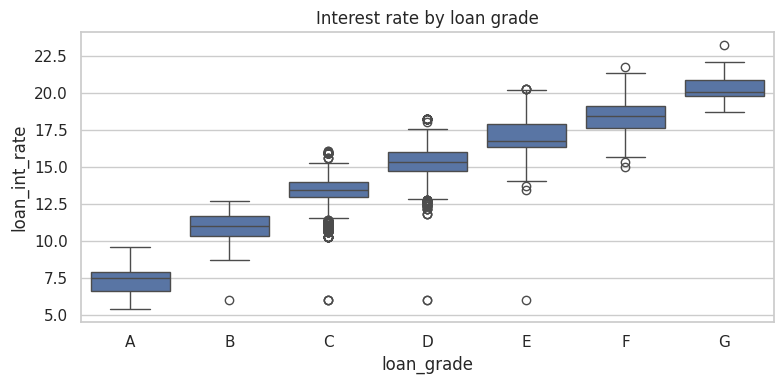

Median interest rate by grade:
loan_grade
A     7.49
B    10.99
C    13.48
D    15.32
E    16.77
F    18.43
G    20.11


In [13]:
expected = (eda["loan_amnt"] / eda["person_income"]).round(2)
gap = (expected - eda["loan_percent_income"]).abs()
print(f"loan_percent_income matches loan_amnt / person_income (tolerance 0.011): {(gap <= 0.011).mean():.2%} of rows")
display(eda.loc[gap > 0.011, ["person_income", "loan_amnt", "loan_percent_income"]].assign(expected=expected[gap > 0.011]).head(10))

fig, ax = plt.subplots(figsize=(8, 4))
order = sorted(eda["loan_grade"].unique())
sns.boxplot(data=eda, x="loan_grade", y="loan_int_rate", order=order, ax=ax)
ax.set_title("Interest rate by loan grade")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_int_rate_by_grade.png", dpi=130, bbox_inches="tight")
plt.show()
print("Median interest rate by grade:")
print(eda.groupby("loan_grade")["loan_int_rate"].median().round(2).to_string())

## 12. Apply the validated cleaning rules (issue #5)

Rule implemented in `src/data/clean.py`: remove rows with an age above 100 or an employment length above 60 years. The thresholds come from the training-set analysis above, and the same rule is applied to train, validation and test. Missing values are **not** handled here: their imputation is learned on the training set inside the scikit-learn pipeline (issue #7).

In [14]:
train_clean = remove_impossible_values(train)
print(f"train: {len(train)} -> {len(train_clean)} rows ({len(train) - len(train_clean)} removed)")
print(f"default rate after cleaning: {train_clean[TARGET].mean():.4f}")
display(train.loc[impossible_mask(train), ["person_age", "person_emp_length", "person_income", "loan_grade", TARGET]])

# Bookkeeping only: how many rows the same fixed rule removes elsewhere (no statistics are computed on them).
for name in ("val", "test"):
    part = load_split(name)
    print(f"{name}: {len(part)} -> {len(remove_impossible_values(part))} rows")

train: 19449 -> 19443 rows (6 removed)
default rate after cleaning: 0.2187


,person_age,person_emp_length,person_income,loan_grade,loan_status
2783,123,2.0,80004,B,0
3159,144,12.0,6000000,C,0
9310,144,4.0,200000,B,0
10693,144,4.0,250000,C,0
15395,22,123.0,59000,D,1
18574,21,123.0,192000,A,0


val: 6483 -> 6482 rows
test: 6484 -> 6484 rows


## 13. Summary and decisions

All figures below come from the **training set** (19,449 rows) after removing exact duplicates.

### Findings

**Data and split**
- 165 exact duplicates removed (0.51% of the raw file); no group of identical features carries conflicting labels.
- Split: 19,449 train / 6,483 validation / 6,484 test rows, with a 21.87% default rate in each part.
- A model that always predicts "no default" reaches 78.1% accuracy, so accuracy is not a useful metric.

**Strongest signals (univariate default rates)**
- `loan_grade`: A 10.0%, B 16.0%, C 21.0%, then a jump to D 59.6%, E 64.0%, F 73.9% and G 100% (only 38 rows).
- `loan_int_rate`: 8.1% in the lowest decile, 60.8% in the highest. `loan_percent_income`: 10.0% in the lowest decile, 70.7% in the highest, with a sharp rise above 0.25.
- `person_income`: 45.6% in the lowest decile, 8.9% in the highest.
- `person_home_ownership`: RENT 31.5%, MORTGAGE 12.9%, OWN 7.5% (OTHER 27.0% on 63 rows only).
- `cb_person_default_on_file`: 38.2% when a past default is on file, 18.4% otherwise.
- Spearman correlation with the target: `loan_int_rate` 0.32, `loan_percent_income` 0.31, `person_income` -0.26. All other numeric variables are below 0.10 in absolute value.

**Shape of the relationships**
- Several relationships are strongly non-linear (thresholds around grade D, interest rate above about 14%, loan-to-income above 0.25). This suggests that tree-based models should do better than a plain logistic regression, which is a hypothesis to test, not a result.
- `person_age` carries little signal (26.5% for age 22 or below, about 20-21% elsewhere). `loan_amnt` is weak, rising only above 12,000.
- `loan_grade` is tightly linked to the interest rate (median 7.49% for A up to 20.11% for G), so these two variables overlap heavily. This supports the planned with/without `loan_grade` study.

**Missing values**
- `person_emp_length`: 541 missing (2.78%). The default rate is **31.2% when missing versus 21.6% when present**, so missingness itself looks informative. It is also higher for OWN (6.9%) than for RENT or MORTGAGE (about 2.4-2.5%).
- `loan_int_rate`: 1,841 missing (9.47%). The default rate is 21.5% when missing versus 21.9% when present, and the missing share stays between 7.9% and 11.6% across grades, so no link with the target or the grade is visible. This does not prove the values are missing at random.

**Anomalies**
- 4 rows with age above 100 (three at 144, one at 123) and 2 rows with an employment length of 123 years (applicants aged 21 and 22): data entry errors.
- 6 rows with income above 1,000,000. None of them defaulted, but 6 rows is too few to conclude anything.
- `loan_percent_income` matches `loan_amnt / person_income` on 98.92% of rows. In the 10 mismatches displayed, the provided ratio is lower than the recomputed one. The cause is unknown.

### Decisions (validated)

| # | Topic | Decision | Where it is implemented |
|---|---|---|---|
| 1 | Age above 100, employment length above 60 | Remove these rows with the same rule on train, validation and test (6 rows in train, 1 in validation, 0 in test). The API rejects such inputs. | `src/data/clean.py` (issue #5) |
| 2 | Income above 1,000,000 | Keep; log-transform or scale robustly for linear models; trees are unaffected | Preprocessing pipeline (issue #7) |
| 3 | Missing `person_emp_length` | Median imputation fitted on train, plus a missing-value indicator (missingness goes with more defaults) | Preprocessing pipeline (issue #7) |
| 4 | Missing `loan_int_rate` | Median imputation by `loan_grade`, fitted on train; revisit if grade is removed | Preprocessing pipeline (issue #7) |
| 5 | `loan_percent_income` | Keep as provided; test the recomputed ratio as an engineered feature | Feature engineering (issue #9) |
| 6 | `loan_grade` | Keep; compare with and without | Dedicated study (issue #19) |